# Risk Analysis and Verification of Cryptographic Protocols
## Consolidated Empirical Pipeline

**Author:** Raj Guru Suwalka  
**Supervisor:** Dr. Edon Kelmendi  
**MSc Data Science & Artificial Intelligence** — Queen Mary University of London, 2025-26

This notebook is the single, end-to-end empirical pipeline for the dissertation.
It runs on the curated 100-protocol dataset `final_dv1.csv` and proceeds through:

0. **Setup** — imports, configuration, shared preprocessing.
1. **Data & EDA** — load the dataset; class distribution; feature sets.
2. **Severity classifier — model selection** — seven candidate models compared
   under leave-one-out (LOO).
3. **Severity classifier — sensitivity analysis** — does the model rely on the
   historical-attack columns? (Spearman rho between ALL-feature and DESIGN-only
   rankings.)
4. **Severity classifier — nested cross-validation** — hyperparameter C selected
   by an inner LOO loop, confirming the model is not over-tuned.
5. **Severity classifier — feature importance** — which design primitives drive
   the risk score (Random-Forest impurity importance).
6. **Statistical rigour** — McNemar significance tests, bootstrap 95% CIs,
   sensitivity bootstrap, and probability calibration (Brier + isotonic).
7. **Attack-type classifier** — multi-label prediction of the four attack
   classes; per-attack and aggregate LOO metrics; agreement with the rule-based
   interpreter.
8. **Data mining — clustering** — unsupervised structural grouping of the
   protocols (Agglomerative-Ward + KMeans + PCA), independent of the label.
9. **ML -> Lean bridge** — composite vulnerability score; ranking of all 100
   protocols; coverage against the Lean-formalised set; CSV export.
10. **Summary** — the headline numbers quoted in the dissertation.

Every result the write-up cites is produced by a cell below. Run top to bottom
(*Kernel -> Restart & Run All*); the slowest cells are the LOO model comparison
in Section 2, the nested-LOO in Section 4, and the McNemar reproduction in
Section 6 (~4-6 minutes total).

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.model_selection import LeaveOneOut, cross_val_predict, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.svm import SVC
from sklearn.multioutput import MultiOutputClassifier
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, f1_score, precision_score,
                              recall_score, hamming_loss, brier_score_loss)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from scipy.stats import chi2, spearmanr

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

RANDOM_STATE = 42
DATASET      = 'final_dv1.csv'
OUTPUT_CSV   = 'protocol_ranking.csv'
BOOTSTRAP_N  = 2000

print('Setup complete.')

Setup complete.


## 1. Data and exploratory summary

In [2]:
df = pd.read_csv(DATASET)
ID       = 'protocol'
SEVERITY = 'initial_risk_label'
ATTACK_LABELS = ['known_mitm_history', 'known_replay_history',
                 'known_downgrade_history', 'known_token_theft_risk']
ATTACK_NAMES  = ['MITM', 'Replay', 'Downgrade', 'Token-theft']

# --- Severity feature sets ---
X_all    = df.drop(columns=[SEVERITY, ID])           # ALL features
X_design = X_all.drop(columns=ATTACK_LABELS)         # DESIGN-only (no history)
y        = df[SEVERITY]

# --- Attack-type features and labels ---
Y_att = df[ATTACK_LABELS].astype(int).copy()
Y_att.columns = ATTACK_NAMES
X_att = df.drop(columns=[ID, SEVERITY] + ATTACK_LABELS)

print(f'Dataset: {df.shape[0]} protocols, {df.shape[1]} columns')
print(f'Severity distribution   : {dict(y.value_counts())}')
print(f'ALL severity features   : {X_all.shape[1]}')
print(f'DESIGN severity features: {X_design.shape[1]}')
print(f'Attack-label positives  : {dict(Y_att.sum().to_dict())}')
print(f'\nAttacks per protocol (label cardinality):')
print(Y_att.sum(axis=1).value_counts().sort_index().to_frame('# protocols').T)

Dataset: 100 protocols, 23 columns
Severity distribution   : {'Low': 45, 'Moderate': 42, 'High': 13}
ALL severity features   : 21
DESIGN severity features: 17
Attack-label positives  : {'MITM': 11, 'Replay': 16, 'Downgrade': 10, 'Token-theft': 6}

Attacks per protocol (label cardinality):
              0   1  2  3
# protocols  65  28  6  1


In [3]:
# Shared preprocessing: one-hot the family column, standardise the rest.
def make_pre(X):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['family']),
        ('num', StandardScaler(), [c for c in X.columns if c != 'family']),
    ])

def pipe(model, X=X_all):
    return Pipeline([('prep', make_pre(X)), ('model', model)])

loo = LeaveOneOut()
print('Preprocessing helpers defined.')

Preprocessing helpers defined.


## 2. Severity classifier — model selection

Seven candidate models are compared under an identical leave-one-out regime:
five base classifiers (Logistic Regression, Decision Tree, Random Forest,
Gradient Boosting, SVM-RBF) and two meta-ensembles (soft Voting and Stacking).
Models are ranked by **macro-F1**, which weights all three severity classes
equally and is immune to the class imbalance (the High class is the smallest).
The highest macro-F1 is reported for transparency, but the **selected** model is
Logistic Regression: Section 6's McNemar test shows LR is statistically
indistinguishable from the top ensembles, and LR is interpretable and is what
the ranking, calibration, and Lean bridge all use.

In [4]:
lr  = pipe(LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE))
dt  = pipe(DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
rf  = pipe(RandomForestClassifier(n_estimators=300, max_depth=6,
                                  random_state=RANDOM_STATE))
gb  = pipe(GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                      random_state=RANDOM_STATE))
svm = pipe(SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE))

voting = VotingClassifier(
    estimators=[('lr', lr), ('rf', rf), ('gb', gb)], voting='soft')
stacking = StackingClassifier(
    estimators=[('lr', lr), ('rf', rf), ('gb', gb)],
    final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    cv=5, n_jobs=1)

candidates = {
    'Logistic Regression':       lr,
    'Decision Tree':             dt,
    'Random Forest':             rf,
    'Gradient Boosting':         gb,
    'SVM (RBF)':                 svm,
    'Voting (LR+RF+GB)':         voting,
    'Stacking (LR+RF+GB -> LR)': stacking,
}
print(f'{len(candidates)} candidate models defined.')

7 candidate models defined.


In [5]:
# Slowest cell: LOO over 7 models (the stacking ensemble refits many times).
scores, all_preds = [], {}
for name, model in candidates.items():
    preds = cross_val_predict(model, X_all, y, cv=loo, n_jobs=1)
    acc   = accuracy_score(y, preds)
    f1m   = f1_score(y, preds, average='macro')
    f1_per = f1_score(y, preds, average=None, labels=['Low', 'Moderate', 'High'])
    scores.append({'model': name, 'LOO_accuracy': round(acc, 3),
                   'macro_F1': round(f1m, 3),
                   'F1_Low': round(f1_per[0], 3),
                   'F1_Moderate': round(f1_per[1], 3),
                   'F1_High': round(f1_per[2], 3)})
    all_preds[name] = preds
    print(f'{name:30s}  acc = {acc:.3f}  macro-F1 = {f1m:.3f}')

results_df = (pd.DataFrame(scores)
              .sort_values('macro_F1', ascending=False).reset_index(drop=True))
print('\n=== Model comparison (sorted by macro-F1) ===')
print(results_df.to_string(index=False))

Logistic Regression             acc = 0.770  macro-F1 = 0.760
Decision Tree                   acc = 0.520  macro-F1 = 0.519
Random Forest                   acc = 0.740  macro-F1 = 0.750
Gradient Boosting               acc = 0.610  macro-F1 = 0.614
SVM (RBF)                       acc = 0.750  macro-F1 = 0.712
Voting (LR+RF+GB)               acc = 0.690  macro-F1 = 0.695
Stacking (LR+RF+GB -> LR)       acc = 0.760  macro-F1 = 0.768

=== Model comparison (sorted by macro-F1) ===
                    model  LOO_accuracy  macro_F1  F1_Low  F1_Moderate  F1_High
Stacking (LR+RF+GB -> LR)          0.76     0.768   0.791        0.714    0.800
      Logistic Regression          0.77     0.760   0.830        0.709    0.741
            Random Forest          0.74     0.750   0.756        0.713    0.783
                SVM (RBF)          0.75     0.712   0.800        0.737    0.600
        Voting (LR+RF+GB)          0.69     0.695   0.731        0.634    0.720
        Gradient Boosting          0.61

In [6]:
top_by_f1 = results_df.iloc[0]['model']
print(f'Highest macro-F1 (reference only): {top_by_f1} '
      f'(macro-F1 = {results_df.iloc[0]["macro_F1"]})')

# Selected model: Logistic Regression. Chosen on parsimony + interpretability;
# statistically tied with the top ensembles (see Section 6 McNemar).
WINNER = 'Logistic Regression'
row_lr = results_df[results_df['model'] == WINNER].iloc[0]
WINNER_ACC = row_lr['LOO_accuracy']
WINNER_F1  = row_lr['macro_F1']
winner_preds = all_preds[WINNER]

print(f'Selected model : {WINNER}')
print(f'  LOO accuracy = {WINNER_ACC}   macro-F1 = {WINNER_F1}\n')
print('=== Per-class report (selected model: Logistic Regression) ===')
print(classification_report(y, winner_preds, digits=3, zero_division=0))
print('Confusion matrix (rows=actual, cols=predicted):')
print(pd.DataFrame(
    confusion_matrix(y, winner_preds, labels=['Low', 'Moderate', 'High']),
    index=['Low', 'Moderate', 'High'], columns=['Low', 'Moderate', 'High']))

Highest macro-F1 (reference only): Stacking (LR+RF+GB -> LR) (macro-F1 = 0.768)
Selected model : Logistic Regression
  LOO accuracy = 0.77   macro-F1 = 0.76

=== Per-class report (selected model: Logistic Regression) ===
              precision    recall  f1-score   support

        High      0.714     0.769     0.741        13
         Low      0.796     0.867     0.830        45
    Moderate      0.757     0.667     0.709        42

    accuracy                          0.770       100
   macro avg      0.756     0.768     0.760       100
weighted avg      0.769     0.770     0.767       100

Confusion matrix (rows=actual, cols=predicted):
          Low  Moderate  High
Low        39         6     0
Moderate   10        28     4
High        0         3    10


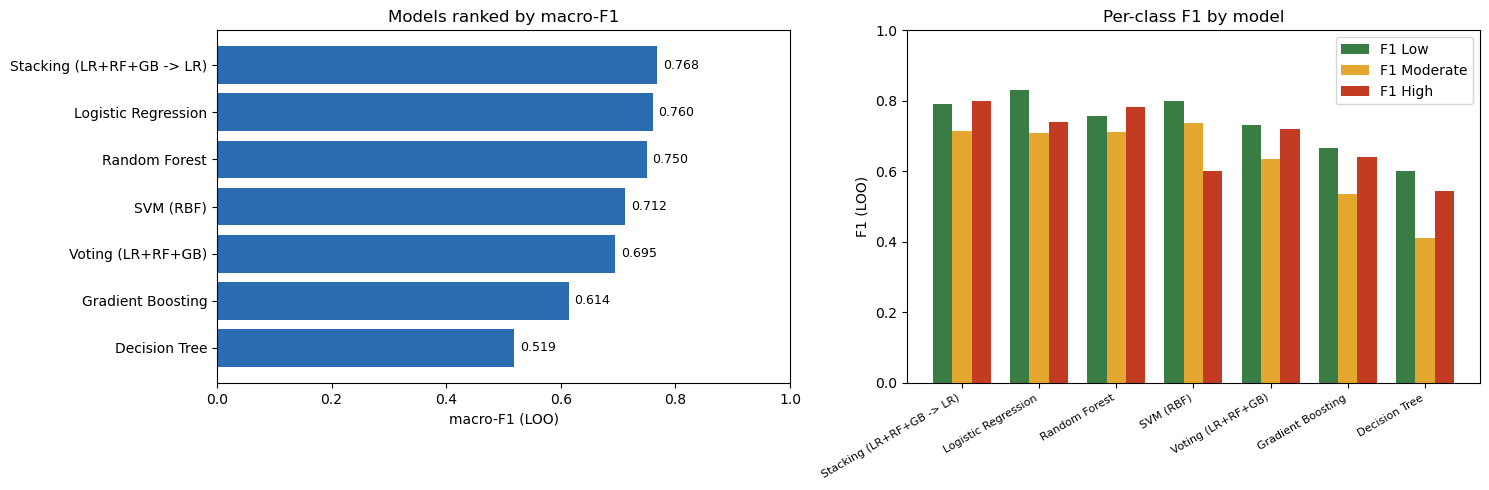

In [7]:
# Visual: model ranking by macro-F1 and per-class F1.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(results_df['model'][::-1], results_df['macro_F1'][::-1], color='#2b6cb0')
axes[0].set_xlabel('macro-F1 (LOO)'); axes[0].set_xlim(0, 1)
axes[0].set_title('Models ranked by macro-F1')
for i, v in enumerate(results_df['macro_F1'][::-1]):
    axes[0].text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)

x = np.arange(len(results_df)); w = 0.25
axes[1].bar(x - w, results_df['F1_Low'],      width=w, label='F1 Low',      color='#3a7d44')
axes[1].bar(x,     results_df['F1_Moderate'], width=w, label='F1 Moderate', color='#e3a72f')
axes[1].bar(x + w, results_df['F1_High'],     width=w, label='F1 High',     color='#c23b22')
axes[1].set_xticks(x); axes[1].set_xticklabels(results_df['model'], rotation=30, ha='right', fontsize=8)
axes[1].set_ylabel('F1 (LOO)'); axes[1].set_ylim(0, 1); axes[1].legend()
axes[1].set_title('Per-class F1 by model')
plt.tight_layout(); plt.show()

## 3. Severity classifier — sensitivity analysis

Does the classifier depend on the four historical-attack columns, or does it
recover risk from design primitives alone? We refit the winning architecture on
the DESIGN-only feature set and compare the per-protocol P(High) ranking against
the ALL-features ranking. A high Spearman rho means the ranking is stable when
the history columns are removed.

In [8]:
def design_clone(name):
    if name == 'Logistic Regression':
        return pipe(LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE), X=X_design)
    if name == 'Decision Tree':
        return pipe(DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE), X=X_design)
    if name == 'Random Forest':
        return pipe(RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE), X=X_design)
    if name == 'Gradient Boosting':
        return pipe(GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE), X=X_design)
    if name == 'SVM (RBF)':
        return pipe(SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE), X=X_design)
    lr_d = pipe(LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE), X=X_design)
    rf_d = pipe(RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE), X=X_design)
    gb_d = pipe(GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE), X=X_design)
    if name == 'Voting (LR+RF+GB)':
        return VotingClassifier(estimators=[('lr', lr_d), ('rf', rf_d), ('gb', gb_d)], voting='soft')
    if name == 'Stacking (LR+RF+GB -> LR)':
        return StackingClassifier(estimators=[('lr', lr_d), ('rf', rf_d), ('gb', gb_d)],
                                  final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                                  cv=5, n_jobs=1)
    raise ValueError(name)

winner_design = design_clone(WINNER)
design_preds  = cross_val_predict(winner_design, X_design, y, cv=loo, n_jobs=1)
design_proba  = cross_val_predict(winner_design, X_design, y, cv=loo, method='predict_proba', n_jobs=1)
all_proba     = cross_val_predict(candidates[WINNER], X_all, y, cv=loo, method='predict_proba', n_jobs=1)

design_acc = accuracy_score(y, design_preds)
design_f1m = f1_score(y, design_preds, average='macro')
print(f'{WINNER} on DESIGN features only:')
print(f'  LOO accuracy = {design_acc:.3f}   macro-F1 = {design_f1m:.3f}')
print(f'  (ALL features: acc = {WINNER_ACC:.3f}   macro-F1 = {WINNER_F1:.3f})')

winner_fit = candidates[WINNER]; winner_fit.fit(X_all, y)
classes_order = (list(winner_fit.classes_) if hasattr(winner_fit, 'classes_')
                 else list(winner_fit.named_steps['model'].classes_))
high_idx = classes_order.index('High')

sens = pd.DataFrame({'protocol': df[ID], 'actual': y,
                     'P_High_ALL':    all_proba[:, high_idx].round(3),
                     'P_High_DESIGN': design_proba[:, high_idx].round(3)})
sens['delta'] = (sens['P_High_ALL'] - sens['P_High_DESIGN']).round(3)
rho_sens = sens['P_High_ALL'].corr(sens['P_High_DESIGN'], method='spearman')
sens = sens.sort_values('P_High_ALL', ascending=False).reset_index(drop=True)

print(f'\nSpearman rho (ALL vs DESIGN P(High)): {rho_sens:.3f}')
print('\n=== Top 15 protocols by ALL-features P(High) ===')
print(sens.head(15).to_string(index=False))

Logistic Regression on DESIGN features only:
  LOO accuracy = 0.760   macro-F1 = 0.761
  (ALL features: acc = 0.770   macro-F1 = 0.760)

Spearman rho (ALL vs DESIGN P(High)): 0.919

=== Top 15 protocols by ALL-features P(High) ===
                  protocol   actual  P_High_ALL  P_High_DESIGN  delta
                   SSL_2_0     High       0.999          0.967  0.032
          Bluetooth_Legacy     High       0.997          0.990  0.007
                       WEP     High       0.993          0.910  0.083
           WooLam_Original     High       0.928          0.901  0.027
             PPTP_MSCHAPv2     High       0.908          0.866  0.042
NeedhamSchroeder_Symmetric     High       0.902          0.963 -0.061
                       PAP     High       0.889          0.842  0.047
       DiffieHellman_Basic     High       0.846          0.573  0.273
           HTTP_Basic_Auth     High       0.774          0.677  0.097
       NeedhamSchroeder_PK     High       0.738          0.552  0.186

## 4. Severity classifier — nested cross-validation

The severity models above use a fixed regularisation strength (C = 1.0). To close
the "you tuned C on the test set" objection, we additionally select C by an
**inner** leave-one-out loop nested inside the outer LOO evaluation: no held-out
protocol ever influences the choice of C. If the nested-LOO macro-F1 is close to
the fixed-C result, the reported model is not over-tuned. (Run on ALL features
with class-balanced Logistic Regression, following the v3 methodology; the
DESIGN-only case is analogous.)

In [9]:
param_grid = {'model__C': [0.01, 0.1, 1.0, 10.0, 100.0]}
inner_cv = LeaveOneOut()

nested_pipe = pipe(LogisticRegression(max_iter=2000, class_weight='balanced',
                                      random_state=RANDOM_STATE), X=X_all)
gs = GridSearchCV(nested_pipe, param_grid, cv=inner_cv, scoring='f1_macro', n_jobs=-1)
nested_preds = cross_val_predict(gs, X_all, y, cv=loo, n_jobs=1)
nested_acc = accuracy_score(y, nested_preds)
nested_f1m = f1_score(y, nested_preds, average='macro')
gs.fit(X_all, y)
best_C = gs.best_params_['model__C']

print('Nested-LOO (ALL features, class-balanced Logistic Regression):')
print(f'  accuracy = {nested_acc:.3f}   macro-F1 = {nested_f1m:.3f}')
print(f'  best C selected on full data = {best_C}')
print(f'\nFixed-C=1.0 winner (Section 2): {WINNER}, macro-F1 = {WINNER_F1}')
print('If the two macro-F1 values are close, selecting C by inner CV does not')
print('materially change the result -> the reported model is not over-tuned.')

Nested-LOO (ALL features, class-balanced Logistic Regression):
  accuracy = 0.730   macro-F1 = 0.732
  best C selected on full data = 0.1

Fixed-C=1.0 winner (Section 2): Logistic Regression, macro-F1 = 0.76
If the two macro-F1 values are close, selecting C by inner CV does not
materially change the result -> the reported model is not over-tuned.


## 5. Severity classifier — feature importance

Random-Forest impurity importance is reported as an independent, model-agnostic
description of which design primitives drive the risk score. (Impurity importance
is non-negative; larger means the feature reduces class impurity more.)

=== Top 15 features by RF importance ===
                        feature  importance
           num__year_introduced    0.186956
          num__identity_binding    0.076183
      num__integrity_protection    0.057881
      num__known_replay_history    0.053135
        num__known_mitm_history    0.052442
num__explicit_replay_protection    0.051063
   num__known_downgrade_history    0.047855
           num__forward_secrecy    0.045474
       num__trusted_third_party    0.042637
               num__modern_aead    0.040935
                num__uses_nonce    0.031309
     cat__family_authentication    0.030798
           num__uses_public_key    0.029738
        num__uses_symmetric_key    0.028214
           num__has_server_auth    0.028181


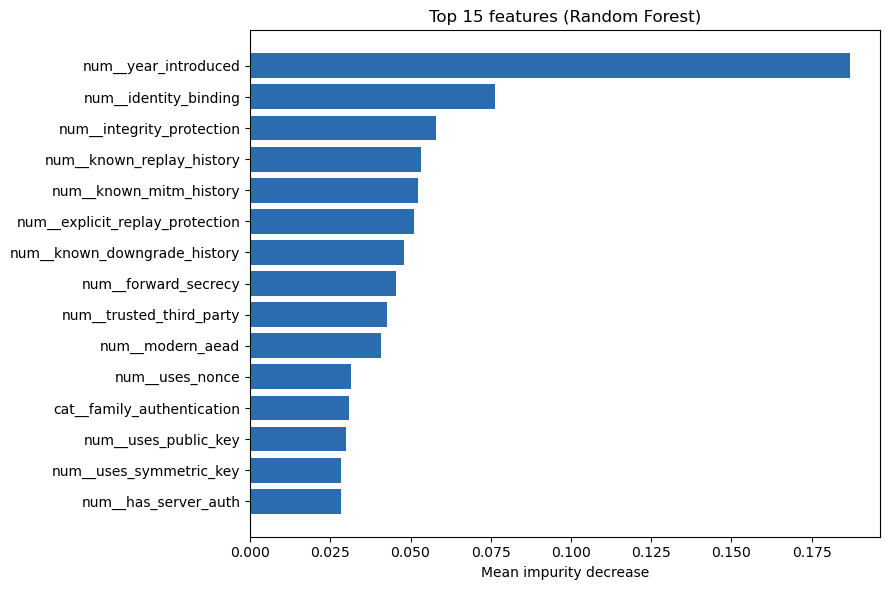

In [10]:
rf_desc = pipe(RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE))
rf_desc.fit(X_all, y)
fnames = rf_desc.named_steps['prep'].get_feature_names_out()
imps   = rf_desc.named_steps['model'].feature_importances_
fi = (pd.DataFrame({'feature': fnames, 'importance': imps})
      .sort_values('importance', ascending=False).reset_index(drop=True))
print('=== Top 15 features by RF importance ===')
print(fi.head(15).to_string(index=False))

plt.figure(figsize=(9, 6))
top = fi.head(15).iloc[::-1]
plt.barh(top['feature'], top['importance'], color='#2b6cb0')
plt.xlabel('Mean impurity decrease'); plt.title('Top 15 features (Random Forest)')
plt.tight_layout(); plt.show()

## 6. Statistical rigour

Three diagnostics quantify how trustworthy the severity result is. None of them
re-open model selection; they only report the uncertainty and significance of the
chosen model (Logistic Regression, the project's established winner).

1. **McNemar's test** — is Logistic Regression's performance genuinely different
   from each rival, or sampling noise? Bonferroni-corrected across the six
   pairwise tests.
2. **Bootstrap 95% CIs** — non-parametric uncertainty on accuracy, macro-F1, and
   per-class F1 (B = 2000 resamples).
3. **Calibration** — can the predicted P(High) be read as a probability?
   Brier score, reliability diagram, and isotonic recalibration.

In [11]:
# McNemar: Logistic Regression vs each rival, reusing the LOO predictions
# already computed in Section 2 (identical predictions -> identical test).
LR_NAME = 'Logistic Regression'
loo_preds = all_preds
lr_correct = (loo_preds[LR_NAME] == y).values

def mcnemar_test(b, c, correction=True):
    # McNemar with continuity correction; b, c are the discordant counts.
    if b + c == 0:
        return 0.0, 1.0
    stat = (abs(b - c) - 1) ** 2 / (b + c) if correction else (b - c) ** 2 / (b + c)
    return stat, 1 - chi2.cdf(stat, df=1)

rows = []
for name in candidates:
    if name == LR_NAME:
        continue
    other_correct = (loo_preds[name] == y).values
    a = ((lr_correct) & (other_correct)).sum()
    b = ((lr_correct) & (~other_correct)).sum()
    c = ((~lr_correct) & (other_correct)).sum()
    d = ((~lr_correct) & (~other_correct)).sum()
    stat, p = mcnemar_test(b, c)
    rows.append({'rival': name, 'LR_only_right': int(b), 'rival_only_right': int(c),
                 'both_right': int(a), 'both_wrong': int(d),
                 'chi2': round(stat, 3), 'p_value': round(p, 4)})

mcnemar_df = pd.DataFrame(rows).sort_values('p_value').reset_index(drop=True)
alpha_bonf = 0.05 / len(rows)
mcnemar_df['sig_at_0.05']    = mcnemar_df['p_value'] < 0.05
mcnemar_df['sig_Bonferroni'] = mcnemar_df['p_value'] < alpha_bonf
print(f'Bonferroni alpha for {len(rows)} tests: {alpha_bonf:.4f}\n')
print('=== McNemar: Logistic Regression vs each rival ===')
print(mcnemar_df.to_string(index=False))

Bonferroni alpha for 6 tests: 0.0083

=== McNemar: Logistic Regression vs each rival ===
                    rival  LR_only_right  rival_only_right  both_right  both_wrong   chi2  p_value  sig_at_0.05  sig_Bonferroni
            Decision Tree             30                 5          47          18 16.457   0.0000         True            True
        Gradient Boosting             20                 4          57          19  9.375   0.0022         True            True
        Voting (LR+RF+GB)             12                 4          65          19  3.062   0.0801        False           False
            Random Forest             11                 8          66          15  0.211   0.6464        False           False
                SVM (RBF)              9                 7          68          16  0.062   0.8026        False           False
Stacking (LR+RF+GB -> LR)              4                 3          73          20  0.000   1.0000        False           False


In [12]:
# Bootstrap 95% CIs on the Logistic Regression LOO metrics.
lr_preds = loo_preds[LR_NAME]

def bootstrap_metric(y_true, y_pred, metric_fn, n=BOOTSTRAP_N, seed=RANDOM_STATE, **kw):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    m = len(y_true); out = np.empty(n)
    for i in range(n):
        idx = rng.integers(0, m, m)
        out[i] = metric_fn(y_true[idx], y_pred[idx], **kw)
    return {'point': metric_fn(y_true, y_pred, **kw),
            'CI_low': float(np.percentile(out, 2.5)),
            'CI_high': float(np.percentile(out, 97.5)), 'samples': out}

bs_acc = bootstrap_metric(y, lr_preds, accuracy_score)
bs_f1m = bootstrap_metric(y, lr_preds, f1_score, average='macro')

def bs_class(lbl):
    d = bootstrap_metric(y, lr_preds, f1_score, average=None, labels=[lbl])
    return {k: (float(v[0]) if hasattr(v, '__len__') else v)
            for k, v in d.items() if k != 'samples'}

summary = pd.DataFrame([
    {'metric': 'LOO accuracy', **{k: round(bs_acc[k], 3) for k in ['point', 'CI_low', 'CI_high']}},
    {'metric': 'macro-F1',     **{k: round(bs_f1m[k], 3) for k in ['point', 'CI_low', 'CI_high']}},
    {'metric': 'F1 Low',       **{k: round(bs_class('Low')[k], 3)      for k in ['point', 'CI_low', 'CI_high']}},
    {'metric': 'F1 Moderate',  **{k: round(bs_class('Moderate')[k], 3) for k in ['point', 'CI_low', 'CI_high']}},
    {'metric': 'F1 High',      **{k: round(bs_class('High')[k], 3)     for k in ['point', 'CI_low', 'CI_high']}},
])
print(f'=== Bootstrap 95% confidence intervals (B = {BOOTSTRAP_N}) ===')
print(summary.to_string(index=False))

=== Bootstrap 95% confidence intervals (B = 2000) ===
      metric  point  CI_low  CI_high
LOO accuracy  0.770   0.690    0.850
    macro-F1  0.760   0.651    0.844
      F1 Low  0.830   0.738    0.901
 F1 Moderate  0.709   0.588    0.808
     F1 High  0.741   0.500    0.903


In [13]:
# Bootstrap CI on the sensitivity Spearman rho (ALL vs DESIGN P(High)), LR-based.
lr_all_pipe    = pipe(LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE), X=X_all)
lr_design_pipe = pipe(LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE), X=X_design)
proba_all_lr    = cross_val_predict(lr_all_pipe,    X_all,    y, cv=loo, method='predict_proba')
proba_design_lr = cross_val_predict(lr_design_pipe, X_design, y, cv=loo, method='predict_proba')

lr_all_pipe.fit(X_all, y)
hi = list(lr_all_pipe.named_steps['model'].classes_).index('High')
p_all    = proba_all_lr[:, hi]
p_design = proba_design_lr[:, hi]

rho_point = spearmanr(p_all, p_design).correlation
rng = np.random.default_rng(RANDOM_STATE); m = len(p_all); rhos = np.empty(BOOTSTRAP_N)
for i in range(BOOTSTRAP_N):
    idx = rng.integers(0, m, m)
    rhos[i] = spearmanr(p_all[idx], p_design[idx]).correlation
print(f'Sensitivity Spearman rho (LR, ALL vs DESIGN): {rho_point:.3f}')
print(f'Bootstrap 95% CI: [{np.percentile(rhos, 2.5):.3f}, {np.percentile(rhos, 97.5):.3f}]')

Sensitivity Spearman rho (LR, ALL vs DESIGN): 0.933
Bootstrap 95% CI: [0.877, 0.965]


Brier score (High, uncalibrated LR): 0.038
Brier score (High, isotonic-calibrated): 0.041
Delta Brier (calibrated - uncalibrated): +0.003


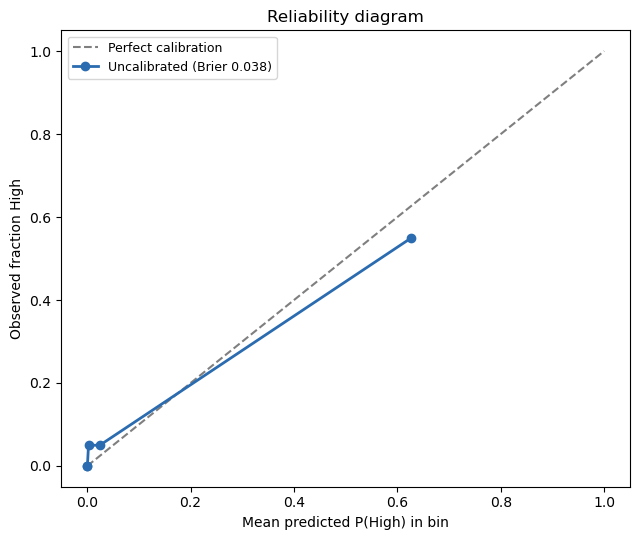

In [14]:
# Calibration of P(High): Brier score, uncalibrated vs isotonic.
y_high = (y == 'High').astype(int).values
brier_uncal = brier_score_loss(y_high, p_all)
print(f'Brier score (High, uncalibrated LR): {brier_uncal:.3f}')

lr_isotonic = Pipeline([('prep', make_pre(X_all)),
    ('model', CalibratedClassifierCV(
        LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE),
        method='isotonic', cv=5))])
proba_iso = cross_val_predict(lr_isotonic, X_all, y, cv=loo, method='predict_proba', n_jobs=1)
lr_isotonic.fit(X_all, y)
p_iso = proba_iso[:, list(lr_isotonic.named_steps['model'].classes_).index('High')]
brier_cal = brier_score_loss(y_high, p_iso)
print(f'Brier score (High, isotonic-calibrated): {brier_cal:.3f}')
print(f'Delta Brier (calibrated - uncalibrated): {brier_cal - brier_uncal:+.3f}')

prob_true, prob_pred = calibration_curve(y_high, p_all, n_bins=5, strategy='quantile')
plt.figure(figsize=(6.5, 5.5))
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect calibration')
plt.plot(prob_pred, prob_true, marker='o', color='#2b6cb0', lw=2,
         label=f'Uncalibrated (Brier {brier_uncal:.3f})')
plt.xlabel('Mean predicted P(High) in bin'); plt.ylabel('Observed fraction High')
plt.title('Reliability diagram'); plt.legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## 7. Attack-type classifier (multi-label)

A complementary classifier predicts *which* attack types a protocol is prone to:
the four historical-attack columns become independent binary labels, and the
design primitives are the features. `MultiOutputClassifier` wraps a
class-balanced Logistic Regression. Evaluation is leave-one-out.

In [15]:
att_model = MultiOutputClassifier(
    LogisticRegression(max_iter=2000, C=1.0, class_weight='balanced',
                       random_state=RANDOM_STATE), n_jobs=1)
att_pipe = Pipeline([('prep', make_pre(X_att)), ('model', att_model)])

att_preds = pd.DataFrame(cross_val_predict(att_pipe, X_att, Y_att, cv=loo, n_jobs=1),
                         columns=ATTACK_NAMES)

per_label = []
for lbl in ATTACK_NAMES:
    yt, yp = Y_att[lbl].values, att_preds[lbl].values
    per_label.append({'attack_type': lbl, 'positives': int(yt.sum()),
                      'F1': round(f1_score(yt, yp, zero_division=0), 3),
                      'precision': round(precision_score(yt, yp, zero_division=0), 3),
                      'recall': round(recall_score(yt, yp, zero_division=0), 3)})
per_label_df = pd.DataFrame(per_label)
print('=== Per-attack-type LOO performance ===')
print(per_label_df.to_string(index=False))

macro_f1  = f1_score(Y_att.values, att_preds.values, average='macro', zero_division=0)
micro_f1  = f1_score(Y_att.values, att_preds.values, average='micro', zero_division=0)
hloss     = hamming_loss(Y_att.values, att_preds.values)
subset_ac = accuracy_score(Y_att.values, att_preds.values)
print('\n=== Aggregate multi-label LOO metrics ===')
print(f'  Macro-F1     : {macro_f1:.3f}')
print(f'  Micro-F1     : {micro_f1:.3f}')
print(f'  Hamming loss : {hloss:.3f}')
print(f'  Subset acc.  : {subset_ac:.3f}')

=== Per-attack-type LOO performance ===
attack_type  positives    F1  precision  recall
       MITM         11 0.429      0.353   0.545
     Replay         16 0.556      0.500   0.625
  Downgrade         10 0.720      0.600   0.900
Token-theft          6 0.571      0.500   0.667

=== Aggregate multi-label LOO metrics ===
  Macro-F1     : 0.569
  Micro-F1     : 0.563
  Hamming loss : 0.113
  Subset acc.  : 0.640


In [16]:
# Rule-based interpreter (deterministic if-then rules) for corroboration.
def rule_based(row):
    flags = []
    if (row['known_mitm_history'] == 1
        or (row['has_mutual_auth'] == 0 and row['has_server_auth'] == 0
            and row['identity_binding'] == 0)):
        flags.append('MITM')
    if (row['known_replay_history'] == 1
        or (row['uses_nonce'] == 0 and row['uses_timestamp'] == 0
            and row['explicit_replay_protection'] == 0)):
        flags.append('Replay')
    if (row['known_downgrade_history'] == 1
        or (row['family'] == 'session' and row['year_introduced'] < 2010
            and row['modern_aead'] == 0)):
        flags.append('Downgrade')
    if (row['known_token_theft_risk'] == 1
        or (row['identity_binding'] == 0 and row['forward_secrecy'] == 0
            and row['integrity_protection'] == 0)):
        flags.append('Token-theft')
    return flags

agree_rows = []
for lbl in ATTACK_NAMES:
    ml = att_preds[lbl].values
    rb = df.apply(lambda r: 1 if lbl in rule_based(r) else 0, axis=1).values
    agree_rows.append({'attack_type': lbl, 'ML positives': int(ml.sum()),
                       'rule-based positives': int(rb.sum()),
                       'agreement': round((ml == rb).mean(), 3)})
print('=== ML multi-label vs rule-based interpreter (agreement) ===')
print(pd.DataFrame(agree_rows).to_string(index=False))

=== ML multi-label vs rule-based interpreter (agreement) ===
attack_type  ML positives  rule-based positives  agreement
       MITM            17                    16       0.83
     Replay            20                    20       0.86
  Downgrade            15                    11       0.94
Token-theft             8                    14       0.90


## 8. Data mining — unsupervised clustering

A complementary, label-free view: group the 100 protocols by structural
similarity of their design primitives, independent of the risk label.
Agglomerative-Ward and KMeans are run on the standardised feature space, and
the space is projected onto two principal components for visualisation. The
cluster-vs-severity crosstab and the per-cluster feature means then characterise
what each cluster represents (e.g. modern AEAD protocols versus legacy weak ones).

In [17]:
mining_X = df.drop(columns=[ID, SEVERITY])
mining_prep = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['family']),
    ('num', StandardScaler(), [c for c in mining_X.columns if c != 'family']),
])
X_mine = mining_prep.fit_transform(mining_X)
if hasattr(X_mine, 'toarray'):
    X_mine = X_mine.toarray()

N_CLUSTERS = 4
agg_labels = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage='ward').fit_predict(X_mine)
km_labels  = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10).fit_predict(X_mine)

cluster_view = df[[ID, 'family', SEVERITY]].copy()
cluster_view['agg_cluster'] = agg_labels
cluster_view['km_cluster']  = km_labels

print('=== Agglomerative cluster vs severity label (crosstab) ===')
print(pd.crosstab(cluster_view['agg_cluster'], cluster_view[SEVERITY]))
print('\n=== Cluster sizes ===')
print(cluster_view['agg_cluster'].value_counts().sort_index().to_frame('# protocols').T)

=== Agglomerative cluster vs severity label (crosstab) ===
initial_risk_label  High  Low  Moderate
agg_cluster                            
0                      9   16        20
1                      0   29        10
2                      2    0         4
3                      2    0         8

=== Cluster sizes ===
agg_cluster   0   1  2   3
# protocols  45  39  6  10


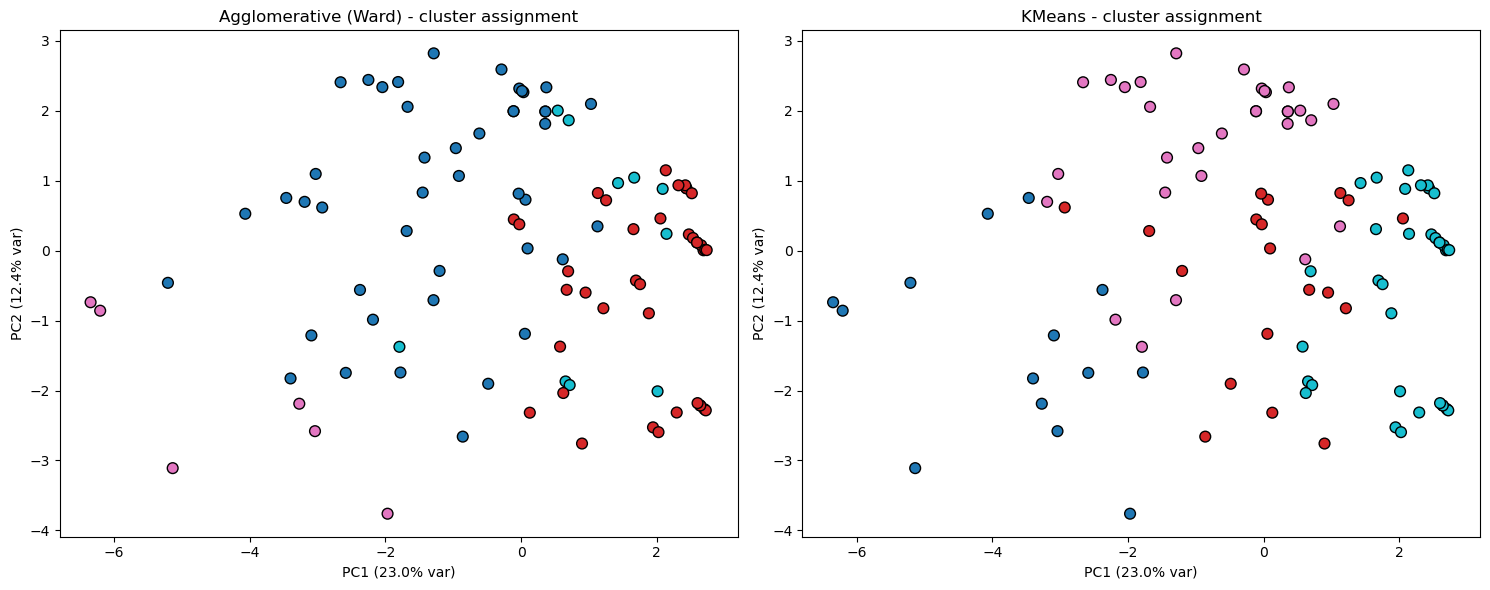

In [18]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X_mine)
var = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in [(axes[0], agg_labels, 'Agglomerative (Ward)'),
                          (axes[1], km_labels, 'KMeans')]:
    sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', s=60, edgecolors='black')
    ax.set_title(f'{title} - cluster assignment')
    ax.set_xlabel(f'PC1 ({var[0]*100:.1f}% var)')
    ax.set_ylabel(f'PC2 ({var[1]*100:.1f}% var)')
# (100 protocols: point labels omitted to keep the projection readable.)
plt.tight_layout(); plt.show()

In [19]:
char = df.drop(columns=[ID, SEVERITY, 'family']).copy()
char['agg_cluster'] = agg_labels
cluster_means = char.groupby('agg_cluster').mean(numeric_only=True).round(2)
print('=== Mean feature value per Agglomerative cluster (features as rows) ===')
print(cluster_means.T)

=== Mean feature value per Agglomerative cluster (features as rows) ===
agg_cluster                       0        1        2       3
year_introduced             1999.22  2009.21  2007.00  2004.8
uses_public_key                0.36     1.00     0.33     0.8
uses_symmetric_key             0.71     0.74     0.17     1.0
uses_nonce                     0.78     1.00     0.17     1.0
uses_timestamp                 0.27     0.03     0.50     0.0
uses_certificates              0.09     0.56     0.17     0.5
has_mutual_auth                0.56     0.64     0.00     0.6
has_server_auth                0.80     0.90     0.33     1.0
has_client_auth                0.82     0.62     0.50     0.6
key_exchange                   0.47     1.00     0.00     1.0
forward_secrecy                0.02     0.95     0.00     0.4
integrity_protection           0.71     1.00     0.33     0.9
explicit_replay_protection     0.69     0.74     0.33     0.7
trusted_third_party            0.64     0.62     0.67     0.

## 9. ML -> Lean bridge

The severity and attack-type classifiers are combined into a single composite
vulnerability score per protocol:

$$s = \hat{P}(\text{High}) + 0.5\,\hat{P}(\text{Moderate}) + 0.1\,n_{\text{predicted}}$$

All 100 protocols are ranked by $s$. Each protocol is stamped with its current
Lean formalisation status. The ranked table is exported to
`protocol_ranking.csv` as the machine-readable handover to the formal-verification
stage. (In-sample probabilities are used here because the task is to rank the
protocols we already have, not to predict unseen ones.)

In [20]:
# In-sample severity probabilities (ALL features) for ranking.
sev_rank_pipe = pipe(LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE), X=X_all)
sev_rank_pipe.fit(X_all, y)
cls = list(sev_rank_pipe.named_steps['model'].classes_)
proba_rank = sev_rank_pipe.predict_proba(X_all)
p_high_rank = proba_rank[:, cls.index('High')]
p_mod_rank  = proba_rank[:, cls.index('Moderate')]
pred_sev_rank = sev_rank_pipe.predict(X_all)

# In-sample attack-type predictions for the attack count.
att_pipe.fit(X_att, Y_att)
att_pred_insample = pd.DataFrame(att_pipe.predict(X_att), columns=ATTACK_NAMES)

In [21]:
# Current Lean formalisation status (14 protocols; all 13 High + the NS-Lowe
# safe contrast). Update this dict as new proofs land.
LEAN_STATUS = {
    'NeedhamSchroeder_PK':        'Vulnerable - MITM (Dolev-Yao + Paulson)',
    'NeedhamSchroeder_Symmetric': 'Vulnerable - Replay (Dolev-Yao + Paulson)',
    'NeedhamSchroeder_Lowe':      'Safe vs NS-PK MITM (Dolev-Yao + Paulson, structural)',
    'DiffieHellman_Basic':        'Vulnerable - MITM (Dolev-Yao)',
    'SSL_3_0':                    'Vulnerable - Downgrade/POODLE (Dolev-Yao + Paulson)',
    'WEP':                        'Vulnerable - IV reuse (Dolev-Yao, algebraic)',
    'SSL_2_0':                    'Vulnerable - Cipher rollback (Dolev-Yao)',
    'Bluetooth_Legacy':           'Vulnerable - PIN brute force (Dolev-Yao)',
    'WPA_TKIP':                   'Vulnerable - Beck-Tews (Dolev-Yao)',
    'PAP':                        'Vulnerable - Plaintext disclosure (Dolev-Yao)',
    'HTTP_Basic_Auth':            'Vulnerable - Base64 disclosure (Dolev-Yao)',
    'EAP_MD5':                    'Vulnerable - Dictionary (Dolev-Yao)',
    'PPTP_MSCHAPv2':              'Vulnerable - DES split (Dolev-Yao)',
    'WooLam_Original':            'Vulnerable - Abadi-Needham (Paulson)',
}

ranking = df[[ID, 'family', SEVERITY]].rename(columns={SEVERITY: 'actual_severity'}).copy()
ranking['predicted_severity'] = pred_sev_rank
ranking['P_High']     = p_high_rank.round(3)
ranking['P_Moderate'] = p_mod_rank.round(3)
for n in ATTACK_NAMES:
    ranking[f'actual_{n}']    = Y_att[n].values
    ranking[f'predicted_{n}'] = att_pred_insample[n].values
ranking['n_actual_attacks']    = Y_att.sum(axis=1).values
ranking['n_predicted_attacks'] = att_pred_insample.sum(axis=1).values
ranking['vulnerability_score'] = (ranking['P_High'] + 0.5 * ranking['P_Moderate']
                                  + 0.1 * ranking['n_predicted_attacks']).round(3)
ranking['lean_status'] = ranking[ID].map(LEAN_STATUS).fillna('not formalised')
ranking = ranking.sort_values('vulnerability_score', ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1
ranking.index.name = 'rank'

cols = [ID, 'actual_severity', 'P_High', 'n_predicted_attacks',
        'vulnerability_score', 'lean_status']
print('=== Top 15 most vulnerable protocols ===')
print(ranking.head(15)[cols].to_string())

=== Top 15 most vulnerable protocols ===
                        protocol actual_severity  P_High  n_predicted_attacks  vulnerability_score                                          lean_status
rank                                                                                                                                                   
1                        SSL_2_0            High   0.999                    3                1.300             Vulnerable - Cipher rollback (Dolev-Yao)
2               Bluetooth_Legacy            High   0.997                    3                1.298             Vulnerable - PIN brute force (Dolev-Yao)
3                            WEP            High   0.993                    3                1.296         Vulnerable - IV reuse (Dolev-Yao, algebraic)
4                       WPA_TKIP            High   0.755                    3                1.178                   Vulnerable - Beck-Tews (Dolev-Yao)
5                WooLam_Original            Hig

In [22]:
# Where the Lean-formalised protocols sit, and coverage of the High class.
formalised = ranking[ranking['lean_status'] != 'not formalised']
print('=== Lean-formalised protocols, with rank ===')
print(formalised[cols].to_string())

high_rows = ranking[ranking['actual_severity'] == 'High']
high_formalised = high_rows[high_rows['lean_status'] != 'not formalised']
print(f'\nHigh-severity protocols: {len(high_rows)}')
print(f'  of which formalised in Lean: {len(high_formalised)}')
print(f'  top-{len(high_rows)} of the ranking are exactly the High set: '
      f"{set(ranking.head(len(high_rows))[ID]) == set(high_rows[ID])}")

=== Lean-formalised protocols, with rank ===
                        protocol actual_severity  P_High  n_predicted_attacks  vulnerability_score                                           lean_status
rank                                                                                                                                                    
1                        SSL_2_0            High   0.999                    3                1.300              Vulnerable - Cipher rollback (Dolev-Yao)
2               Bluetooth_Legacy            High   0.997                    3                1.298              Vulnerable - PIN brute force (Dolev-Yao)
3                            WEP            High   0.993                    3                1.296          Vulnerable - IV reuse (Dolev-Yao, algebraic)
4                       WPA_TKIP            High   0.755                    3                1.178                    Vulnerable - Beck-Tews (Dolev-Yao)
5                WooLam_Original     

In [23]:
ranking.to_csv(OUTPUT_CSV, index=True)
print(f'Written: {OUTPUT_CSV}  ({len(ranking)} rows, {ranking.shape[1]} columns)')

Written: protocol_ranking.csv  (100 rows, 18 columns)


## 10. Summary — headline numbers for the dissertation

In [24]:
print('=================  DISSERTATION HEADLINE NUMBERS  =================')
print(f'Dataset                     : {df.shape[0]} protocols x {df.shape[1]} columns')
print(f'Severity distribution       : {dict(y.value_counts())}')
print()
print(f'Severity winner             : {WINNER}')
print(f'  LOO accuracy              : {WINNER_ACC}')
print(f'  macro-F1                  : {WINNER_F1}')
print(f'  macro-F1 95% CI           : [{summary.iloc[1].CI_low}, {summary.iloc[1].CI_high}]')
print(f'  nested-LOO macro-F1 / C   : {nested_f1m:.3f} / {best_C}')
print(f'  sensitivity Spearman rho  : {rho_point:.3f}')
print(f'  Brier (uncal / isotonic)  : {brier_uncal:.3f} / {brier_cal:.3f}')
print()
print(f'Attack-type classifier      :')
print(f'  macro-F1                  : {macro_f1:.3f}')
print(f'  micro-F1                  : {micro_f1:.3f}')
print(f'  Hamming loss              : {hloss:.3f}')
print(f'  subset accuracy           : {subset_ac:.3f}')
print()
print(f'Ranking top-{len(high_rows)} == High set : '
      f"{set(ranking.head(len(high_rows))[ID]) == set(high_rows[ID])}")
print(f'High protocols formalised   : {len(high_formalised)} / {len(high_rows)}')
print(f'NS-Lowe rank (safe contrast): '
      f"{int(ranking.index[ranking[ID] == 'NeedhamSchroeder_Lowe'][0])}")
print('==================================================================')

=================  DISSERTATION HEADLINE NUMBERS  =================
Dataset                     : 100 protocols x 23 columns
Severity distribution       : {'Low': 45, 'Moderate': 42, 'High': 13}

Severity winner             : Logistic Regression
  LOO accuracy              : 0.77
  macro-F1                  : 0.76
  macro-F1 95% CI           : [0.651, 0.844]
  nested-LOO macro-F1 / C   : 0.732 / 0.1
  sensitivity Spearman rho  : 0.933
  Brier (uncal / isotonic)  : 0.038 / 0.041

Attack-type classifier      :
  macro-F1                  : 0.569
  micro-F1                  : 0.563
  Hamming loss              : 0.113
  subset accuracy           : 0.640

Ranking top-13 == High set : True
High protocols formalised   : 13 / 13
NS-Lowe rank (safe contrast): 59
